# Vitrine Avançada: Variantes do LS-SVM em Prognose Florestal

Este notebook mostra o que o `experimental-ml` oferece quando sua pesquisa avança para estudos mais exigentes:
- Comparação controlada de **3 variantes arquiteturais do LS-SVM** (Clássico RBF, Kernel Quântico e Solver Linear Quântico) sobre exatamente as mesmas dobras;
- Avaliação de `rmse`, `rmse_rel_pct`, `mbe` e `r2`, inferência pareada (Nadeau-Bengio / Wilcoxon) e **Fronteira de Pareto**;
- Geração completa de relatórios (`report.md`, `report.html`), código **LaTeX `booktabs`**, gráficos **SVG** e pacote de reprodutibilidade `reduced_no_raw_data` para leitura direta aqui no notebook.

In [1]:
# Instalação automática apenas quando executado no Google Colab
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/aleerangel/experimental-ml-framework.git",
    ])

In [2]:
# Helper de exibição rica (funciona em Jupyter/Colab e em Python puro)
def exibir_markdown(texto: str) -> None:
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except ImportError:
        print(texto)

def exibir_svg(svg_bytes: bytes | str) -> None:
    svg_str = svg_bytes.decode("utf-8") if isinstance(svg_bytes, bytes) else svg_bytes
    try:
        from IPython.display import SVG, display
        display(SVG(svg_str))
    except ImportError:
        print(f"[Figura SVG gerada: {len(svg_str)} caracteres]")

## 1. Base de Prognose Florestal e Implementação das Variantes LS-SVM

In [3]:
from pathlib import Path
import tempfile
import numpy as np

from experimental_ml.core.enums import MetricDirection, TaskType
from experimental_ml.data import (
    DatasetSchemaSpec,
    create_preparation_plan,
    load_dataset,
    profile_dataset,
    sanitize_dataset,
)
from experimental_ml.features import FeatureScenario, ScenarioMode
from experimental_ml.models import (
    ModelCapabilities,
    ModelFamily,
    ModelSpec,
    validate_model_spec,
)

class LSSVMVariante:
    def __init__(self, kernel_mode: str = "rbf_classico", gamma: float = 0.01, reg: float = 10.0) -> None:
        self.kernel_mode = kernel_mode
        self.gamma = gamma
        self.reg = reg
        self.X_train_ = None
        self.alpha_ = None
        self.b_ = 0.0

    def _gram(self, A: np.ndarray, B: np.ndarray) -> np.ndarray:
        if self.kernel_mode == "kernel_quantico":
            An = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
            Bn = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
            return (np.cos(An @ Bn.T)) ** 2
        sq = np.sum(A ** 2, axis=1, keepdims=True) + np.sum(B ** 2, axis=1) - 2.0 * (A @ B.T)
        return np.exp(-self.gamma * np.maximum(sq, 0.0))

    def fit(self, X: np.ndarray, y: np.ndarray) -> "LSSVMVariante":
        n = X.shape[0]
        self.X_train_ = X.copy()
        K = self._gram(X, X) + (1.0 / self.reg) * np.eye(n)
        ones = np.ones((n, 1))
        A_mat = np.block([[np.zeros((1, 1)), ones.T], [ones, K]])
        rhs = np.concatenate([[0.0], y])
        sol = np.linalg.solve(A_mat + 1e-9 * np.eye(n + 1), rhs)
        self.b_ = float(sol[0])
        self.alpha_ = sol[1:]
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self._gram(X, self.X_train_) @ self.alpha_ + self.b_

rng = np.random.default_rng(7)
dap = rng.uniform(10.0, 35.0, size=40)
altura = 8.0 + 0.6 * dap + rng.normal(0.0, 1.0, size=40)
idade = rng.integers(3, 12, size=40).astype(float)
volume = 0.00005 * (dap ** 2) * altura + rng.normal(0.0, 0.02, size=40)

schema = DatasetSchemaSpec(target_col="volume", task_type=TaskType.REGRESSION)
bundle = load_dataset({"dap": dap, "altura": altura, "idade": idade, "volume": volume}, schema)
profile = profile_dataset(bundle)
view = sanitize_dataset(bundle, profile, create_preparation_plan(profile, rules=[]))
print(f"Base florestal carregada: {len(view.observation_ids)} parcelas.")

Base florestal carregada: 40 parcelas.


## 2. Execução Matricial Controlada, Inferência Pareada e Fronteira de Pareto

In [4]:
from experimental_ml.orchestration import load_cell_artifacts, run_experiment_matrix
from experimental_ml.statistics import (
    ComparisonScope,
    ComparisonSpec,
    MultiObjectiveSpec,
    ObjectiveSource,
    ObjectiveSpec,
    compute_pareto_frontier,
    consolidate_descriptive,
    evaluate_method_suitability,
    run_statistical_comparisons,
    save_statistics_artifacts,
    synthesize_conclusions,
)
from experimental_ml.validation import (
    EvaluationRegime,
    PartitionConfig,
    PartitionStrategy,
    build_partition_plan,
)

specs = [
    validate_model_spec(ModelSpec(
        model_id="lssvm_rbf",
        display_name="LS-SVM Clássico (RBF)",
        family=ModelFamily.CLASSICAL_ML,
        estimator_factory=lambda seed=None, **kw: LSSVMVariante(**kw),
        capabilities=ModelCapabilities(requires_fit=True),
        parameters={"kernel_mode": "rbf_classico", "gamma": 0.01, "reg": 10.0},
        description="Kernel RBF clássico",
        scientific_justification="Baseline clássico",
    )),
    validate_model_spec(ModelSpec(
        model_id="lssvm_qkernel",
        display_name="LS-SVM (Kernel Quântico)",
        family=ModelFamily.QUANTUM_KERNEL,
        estimator_factory=lambda seed=None, **kw: LSSVMVariante(**kw),
        capabilities=ModelCapabilities(requires_fit=True, supports_precomputed_kernel=True),
        parameters={"kernel_mode": "kernel_quantico", "reg": 10.0},
        description="Kernel quântico de fidelidade",
        scientific_justification="Avaliação de mapa de características quântico",
    )),
    validate_model_spec(ModelSpec(
        model_id="lssvm_qsolver",
        display_name="LS-SVM (Solver Quântico)",
        family=ModelFamily.QUANTUM_SOLVER,
        estimator_factory=lambda seed=None, **kw: LSSVMVariante(**kw),
        capabilities=ModelCapabilities(requires_fit=True),
        parameters={"kernel_mode": "solver_quantico", "gamma": 0.01, "reg": 10.0},
        description="Solver linear quântico",
        scientific_justification="Comparação do solver linear KKT",
    )),
]

cenario = FeatureScenario(
    scenario_id="dendrometria",
    name="Variáveis Dendrométricas",
    description="DAP, altura e idade",
    scientific_justification="Preditores padrão de volume florestal",
    mode=ScenarioMode.FIXED,
    selected_features=("dap", "altura", "idade"),
)

part_plan = build_partition_plan(
    view,
    PartitionConfig(strategy=PartitionStrategy.KFOLD, regime=EvaluationRegime.CV_ONLY, n_splits=5, master_seed=42),
)
exp_dir = Path(tempfile.mkdtemp(prefix="expml_avancado_03_"))
state = run_experiment_matrix(
    model_specs=specs,
    scenarios=[cenario],
    partition_plan=part_plan,
    sanitized_view=view,
    run_dir=exp_dir / "runs",
    metrics=("rmse", "rmse_rel_pct", "mbe", "r2"),
    master_seed=42,
    overwrite=True,
)

cells = [load_cell_artifacts(cid, exp_dir / "runs")[0] for cid in state.cell_statuses]
cons = consolidate_descriptive(
    cells,
    total_folds_per_config=len(part_plan.folds),
    experiment_id=state.experiment_id,
    partition_plan_id=part_plan.plan_id,
)
suit = evaluate_method_suitability(part_plan, cons)
comp = run_statistical_comparisons(
    cons, part_plan,
    ComparisonSpec(
        metrics_of_interest=("rmse", "rmse_rel_pct", "mbe"),
        metric_directions={
            "rmse": MetricDirection.MINIMIZE,
            "rmse_rel_pct": MetricDirection.MINIMIZE,
            "mbe": MetricDirection.MINIMIZE,
        },
        comparison_scope=ComparisonScope.ALL_PAIRWISE,
        alpha=0.05,
    ),
    suit,
)
pareto = compute_pareto_frontier(
    cons,
    MultiObjectiveSpec(objectives=(
        ObjectiveSpec(name="rmse", source=ObjectiveSource.AGGREGATED_METRIC, direction=MetricDirection.MINIMIZE, field_name="rmse"),
        ObjectiveSpec(name="latencia", source=ObjectiveSource.TIMING_MEAN, direction=MetricDirection.MINIMIZE, field_name="predict_mean_s"),
    )),
)
conc = synthesize_conclusions(cons, suit, comp, primary_metric="rmse", primary_direction=MetricDirection.MINIMIZE, multi_objective_summary=pareto)
save_statistics_artifacts(exp_dir / "statistics", cons, suit, comp, conc, pareto=pareto, force=True)
print(f"Líder em RMSE: {conc.observed_leader} | Evidência: {conc.statistical_evidence_status}")

Líder em RMSE: ('lssvm_qsolver', 'dendrometria') | Evidência: 0 of 3 comparison(s) reached adjusted significance (p_adj < 0.050); 3 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence).


## 3. Geração e Leitura Completa dos Relatórios, LaTeX, SVG e Pacote de Conferência

Prévia do código LaTeX (Desempenho Preditivo):
\begin{table}[htbp]
\centering
\caption{Cross-validation descriptive performance}
\begin{tabular}{lllcrrrrr}
\toprule
Model & Scenario & Metric & Status & Mean & SD & Median & IQR & Coverage \\
\midrule
lssvm\_qkernel & dendrometria & mbe & VALID & 16.7556 & 30.3464 & 7.9580 & 7.2765 & 100.00\% \\
lssvm\_qkernel & dendrometria & r2 & VALID & -30728.5773 & 59597.7493 & -2149.660
Pacote exportado (REDUCED_NO_RAW_DATA): 35 artefatos com checksums SHA-256.


# Scientific Experiment Report — exp_matrix

- **Experiment ID:** `exp_matrix`
- **Partition Plan ID:** `85b4e778775e73229d5babcdef1dd294a70d02b943c0dbf9f34cc4e150007a70`
- **Evaluation Regime:** `CV_ONLY` ($J = 5$)

## 1. Researcher Declarations (Declared Provenance)

_No explicit researcher declarations provided._

## 2. Registered Computational Facts

### Data Characterization

| Attribute | Value |
| :--- | ---: |

### Feature Scenarios

| Scenario | Selection Mode | Features |
| :--- | :--- | ---: |

### Models Configuration

| Model ID | Model Family | Task Type |
| :--- | :--- | :--- |

### Predictive Performance

| Model | Scenario | Metric | Status | Mean | SD | Median | IQR | Coverage |
| :--- | :--- | :--- | :---: | ---: | ---: | ---: | ---: | ---: |
| lssvm_qkernel | dendrometria | mbe | VALID | 16.7556 | 30.3464 | 7.9580 | 7.2765 | 100.00% |
| lssvm_qkernel | dendrometria | r2 | VALID | -30728.5773 | 59597.7493 | -2149.6603 | 13973.1001 | 100.00% |
| lssvm_qkernel | dendrometria | rmse | VALID | 44.3533 | 69.6680 | 21.4436 | 13.0556 | 100.00% |
| lssvm_qkernel | dendrometria | rmse_rel_pct | VALID | 9155.0744 | 14757.4545 | 2695.6356 | 5515.9969 | 100.00% |
| lssvm_qsolver | dendrometria | mbe | VALID | -0.0067 | 0.0274 | 0.0092 | 0.0485 | 100.00% |
| lssvm_qsolver | dendrometria | r2 | VALID | 0.9743 | 0.0201 | 0.9734 | 0.0224 | 100.00% |
| lssvm_qsolver | dendrometria | rmse | VALID | 0.0657 | 0.0442 | 0.0478 | 0.0801 | 100.00% |
| lssvm_qsolver | dendrometria | rmse_rel_pct | VALID | 10.2778 | 4.8590 | 10.0199 | 4.4543 | 100.00% |
| lssvm_rbf | dendrometria | mbe | VALID | -0.0067 | 0.0274 | 0.0092 | 0.0485 | 100.00% |
| lssvm_rbf | dendrometria | r2 | VALID | 0.9743 | 0.0201 | 0.9734 | 0.0224 | 100.00% |
| lssvm_rbf | dendrometria | rmse | VALID | 0.0657 | 0.0442 | 0.0478 | 0.0801 | 100.00% |
| lssvm_rbf | dendrometria | rmse_rel_pct | VALID | 10.2778 | 4.8590 | 10.0199 | 4.4543 | 100.00% |

### Statistical Comparisons

| Config A | Config B | Metric | Diff | t (NB) | p_adj (NB) | p_adj (WX) | Cohen d_z | Practical Relevance |
| :--- | :--- | :--- | ---: | ---: | ---: | ---: | ---: | :--- |
| lssvm_qkernel/dendrometria | lssvm_qsolver/dendrometria | rmse | 44.2876 | 0.9474 | 1.0000 | 0.1875 | 0.6356 | NOT_CONFIGURED |
| lssvm_qkernel/dendrometria | lssvm_rbf/dendrometria | rmse | 44.2876 | 0.9474 | 1.0000 | 0.1875 | 0.6356 | NOT_CONFIGURED |
| lssvm_qsolver/dendrometria | lssvm_rbf/dendrometria | rmse | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| lssvm_qkernel/dendrometria | lssvm_qsolver/dendrometria | rmse_rel_pct | 9144.7966 | 0.9237 | 1.0000 | 0.1875 | 0.6196 | NOT_CONFIGURED |
| lssvm_qkernel/dendrometria | lssvm_rbf/dendrometria | rmse_rel_pct | 9144.7966 | 0.9237 | 1.0000 | 0.1875 | 0.6196 | NOT_CONFIGURED |
| lssvm_qsolver/dendrometria | lssvm_rbf/dendrometria | rmse_rel_pct | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |
| lssvm_qkernel/dendrometria | lssvm_qsolver/dendrometria | mbe | 16.7624 | 0.8237 | 1.0000 | 0.5625 | 0.5526 | NOT_CONFIGURED |
| lssvm_qkernel/dendrometria | lssvm_rbf/dendrometria | mbe | 16.7624 | 0.8237 | 1.0000 | 0.5625 | 0.5526 | NOT_CONFIGURED |
| lssvm_qsolver/dendrometria | lssvm_rbf/dendrometria | mbe | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | NOT_CONFIGURED |

### Stability, Cost & Pareto

| Model | Scenario | Fit Time (s) | Total Time (s) | Stability (Jaccard) | Pareto Optimal |
| :--- | :--- | ---: | ---: | ---: | :---: |
| lssvm_qkernel | dendrometria | 0.0003 | 0.0008 | 1.0000 | False |
| lssvm_qsolver | dendrometria | 0.0002 | 0.0007 | 1.0000 | False |
| lssvm_rbf | dendrometria | 0.0002 | 0.0006 | 1.0000 | True |

### Model-Specific Artifacts

| Model | Artifact | Summary |
| :--- | :--- | :--- |

> Note: No model-specific adapter diagnostics exported.

## 3. Derived and Conditioned Interpretations

- **Primary Metric:** `rmse`
- **Observed Leader:** `('lssvm_qsolver', 'dendrometria')`
- **Statistical Evidence:** 0 of 3 comparison(s) reached adjusted significance (p_adj < 0.050); 3 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence).
- **Effect Magnitude:** lssvm_qkernel/dendrometria vs lssvm_qsolver/dendrometria: MEDIUM (d_z=0.6356); lssvm_qkernel/dendrometria vs lssvm_rbf/dendrometria: MEDIUM (d_z=0.6356); lssvm_qsolver/dendrometria vs lssvm_rbf/dendrometria: NEGLIGIBLE (d_z=0.0000)
- **Practical Relevance:** NOT_CONFIGURED
- **Cost & Pareto Trade-off:** Pareto frontier contains 1 configuration(s): lssvm_rbf/dendrometria (2 dominated, 0 excluded).

### Narrative Synthesis

On primary metric 'rmse' (MINIMIZE), observed leader is lssvm_qsolver/dendrometria with mean=0.0657. 0 of 3 comparison(s) reached adjusted significance (p_adj < 0.050); 3 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence). Comparison lssvm_qkernel/dendrometria vs lssvm_qsolver/dendrometria: diff=44.2876, t=0.9474, p_adj=1.0000 (Nadeau-Bengio), W=0.0, wx_p_adj=0.1875, d_z=0.6356 [MEDIUM], practical=NOT_CONFIGURED. Comparison lssvm_qkernel/dendrometria vs lssvm_rbf/dendrometria: diff=44.2876, t=0.9474, p_adj=1.0000 (Nadeau-Bengio), W=0.0, wx_p_adj=0.1875, d_z=0.6356 [MEDIUM], practical=NOT_CONFIGURED. Comparison lssvm_qsolver/dendrometria vs lssvm_rbf/dendrometria: diff=0.0000, t=0.0000, p_adj=1.0000 (Nadeau-Bengio), W=0.0, wx_p_adj=1.0000, d_z=0.0000 [NEGLIGIBLE], practical=NOT_CONFIGURED. Pareto frontier contains 1 configuration(s): lssvm_rbf/dendrometria (2 dominated, 0 excluded). Caveats: Small sample size (J = 5 < 6) severely limits statistical power for non-parametric paired tests.

### Methodological Caveats

- Small sample size (J = 5 < 6) severely limits statistical power for non-parametric paired tests.


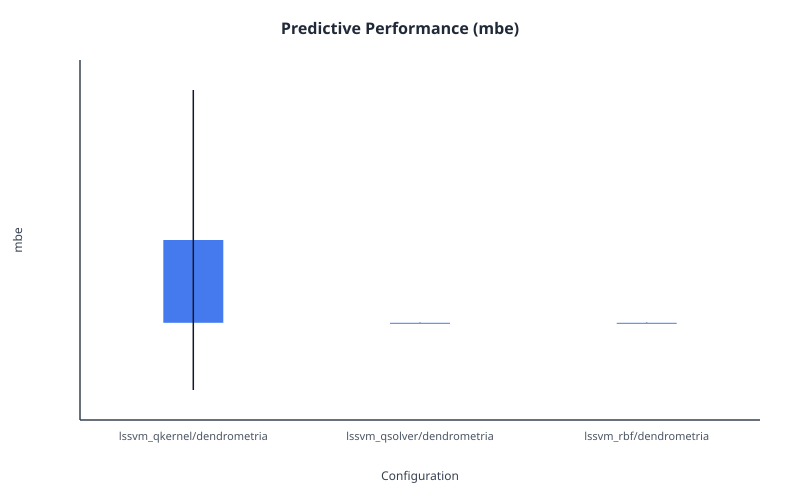

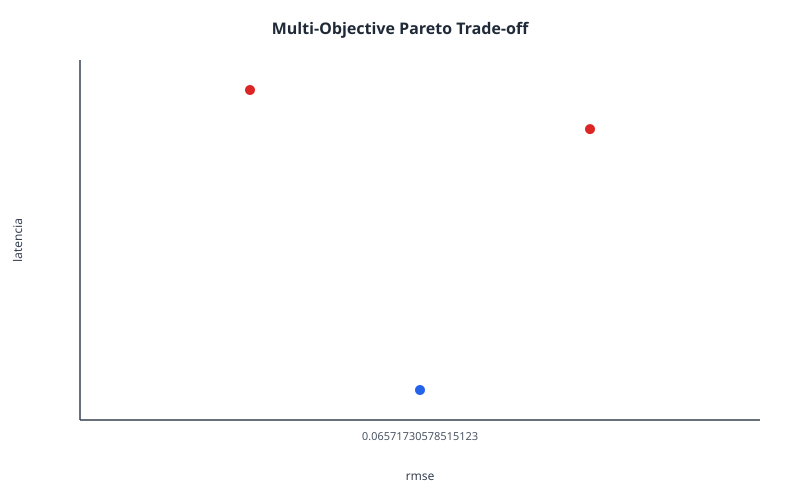

In [5]:
from experimental_ml.reporting import (
    PackageMode,
    ReportAudience,
    ReportContentSelection,
    ReportFamily,
    build_figure_spec,
    build_reproducibility_package,
    build_table_model,
    load_experiment_artifacts_readonly,
    render_figure,
    render_full_report,
    render_table_latex,
    render_table_markdown,
    select_report_content,
)

loaded = load_experiment_artifacts_readonly(exp_dir)
sel = select_report_content(loaded, ReportContentSelection(audience=ReportAudience.FULL_LAB))

# 1. Relatórios completos salvos em disco (Markdown + HTML) e exibidos para leitura
reports_dir = exp_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)
report_md = render_full_report(loaded, fmt="markdown", selection=sel)
(reports_dir / "report.md").write_text(report_md, encoding="utf-8")
(reports_dir / "report.html").write_text(render_full_report(loaded, fmt="html", selection=sel), encoding="utf-8")
exibir_markdown(report_md)

# 2. Tabela LaTeX booktabs pronta para artigo
tbl_perf = build_table_model(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
print("Prévia do código LaTeX (Desempenho Preditivo):")
print(render_table_latex(tbl_perf)[:380])

# 3. Gráficos SVG inline (Desempenho e Fronteira de Pareto)
exibir_svg(render_figure(build_figure_spec(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel), fmt="svg"))
exibir_svg(render_figure(build_figure_spec(ReportFamily.F_STABILITY_COST_PARETO, loaded, sel), fmt="svg"))

# 4. Pacote portátil para conferências (sem dados brutos)
pacote_dir = exp_dir / "pacote_conferencia"
manifest = build_reproducibility_package(
    loaded,
    output_dir=pacote_dir,
    mode=PackageMode.REDUCED_NO_RAW_DATA,
    source_experiment_dir=exp_dir,
    force=True,
)
print(f"Pacote exportado ({manifest.reproduction_level}): {len(manifest.exported_files)} artefatos com checksums SHA-256.")